In [1]:
# ============================================================
# LAB - Q-LEARNING
# Autonomous Retail Checkout Queue Optimizer
#
# State:
#       (q0, q1, q2)
#
# Action:
#       0 -> Route customer to Lane 0
#       1 -> Route customer to Lane 1
#       2 -> Route customer to Lane 2
#
# Algorithm:
#       Tabular Q-Learning
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from itertools import product


# ============================================================
# RANDOM SEED
# ============================================================

SEED = 42

np.random.seed(SEED)


# ============================================================
# ENVIRONMENT CONFIGURATION
# ============================================================

NUM_LANES = 3

MAX_QUEUE = 5

NUM_ACTIONS = 3

NUM_STATES = (MAX_QUEUE + 1) ** NUM_LANES


# ============================================================
# Q-LEARNING PARAMETERS
# ============================================================

ALPHA = 0.10

GAMMA = 0.90

EPSILON_START = 1.0

EPSILON_MIN = 0.05

EPSILON_DECAY = 0.995

EPISODES = 5000

STEPS_PER_EPISODE = 100


# ============================================================
# SERVICE PROBABILITIES
# ============================================================

# Probability that one customer is served
# from each lane during one time step.

SERVICE_PROBABILITY = np.array([
    0.70,
    0.60,
    0.80
])


# ============================================================
# REWARD PARAMETERS
# ============================================================

WAITING_COST = -1.0

SERVICE_REWARD = 5.0

OVERFLOW_PENALTY = -20.0

EMPTY_SYSTEM_REWARD = 2.0


# ============================================================
# STATE SPACE
# ============================================================

STATES = list(
    product(
        range(MAX_QUEUE + 1),
        repeat=NUM_LANES
    )
)


STATE_TO_INDEX = {
    state: i
    for i, state in enumerate(STATES)
}


In [2]:
# ============================================================
# ENVIRONMENT
# ============================================================

class CheckoutEnvironment:

    def __init__(self):

        self.state = None


    # --------------------------------------------------------
    # RESET
    # --------------------------------------------------------

    def reset(self):

        self.state = (
            0,
            0,
            0
        )

        return self.state


    # --------------------------------------------------------
    # STEP
    # --------------------------------------------------------

    def step(self, action):

        queues = list(self.state)

        reward = 0.0


        # ====================================================
        # CUSTOMER ARRIVAL
        # ====================================================

        if queues[action] < MAX_QUEUE:

            queues[action] += 1

        else:

            reward += OVERFLOW_PENALTY


        # ====================================================
        # STOCHASTIC SERVICE
        # ====================================================

        customers_served = 0


        for lane in range(NUM_LANES):

            if queues[lane] > 0:

                if (
                    np.random.random()
                    <
                    SERVICE_PROBABILITY[lane]
                ):

                    queues[lane] -= 1

                    customers_served += 1


        # ====================================================
        # SERVICE REWARD
        # ====================================================

        reward += (
            SERVICE_REWARD
            *
            customers_served
        )


        # ====================================================
        # WAITING COST
        # ====================================================

        total_queue = sum(queues)

        reward += (
            WAITING_COST
            *
            total_queue
        )


        # ====================================================
        # EMPTY SYSTEM BONUS
        # ====================================================

        if total_queue == 0:

            reward += EMPTY_SYSTEM_REWARD


        # ====================================================
        # NEXT STATE
        # ====================================================

        next_state = tuple(queues)

        self.state = next_state


        return (
            next_state,
            reward
        )



In [3]:

# ============================================================
# EPSILON-GREEDY POLICY
# ============================================================

def choose_action(
    Q,
    state_index,
    epsilon
):

    # --------------------------------------------------------
    # Exploration
    # --------------------------------------------------------

    if np.random.random() < epsilon:

        return np.random.randint(
            NUM_ACTIONS
        )


    # --------------------------------------------------------
    # Exploitation
    # --------------------------------------------------------

    q_values = Q[state_index]

    max_q = np.max(q_values)


    # Random tie breaking
    # avoids always selecting Lane 0
    # when Q-values are equal.

    best_actions = np.flatnonzero(
        np.isclose(
            q_values,
            max_q
        )
    )


    return np.random.choice(
        best_actions
    )


# ============================================================
# Q-LEARNING TRAINING
# ============================================================

def train_q_learning():

    # --------------------------------------------------------
    # Initialize Q-table
    # --------------------------------------------------------

    Q = np.zeros(
        (
            NUM_STATES,
            NUM_ACTIONS
        )
    )


    env = CheckoutEnvironment()


    epsilon = EPSILON_START


    # --------------------------------------------------------
    # Logging
    # --------------------------------------------------------

    episode_rewards = []

    epsilon_history = []

    td_error_history = []

    q_change_history = []


    # ========================================================
    # TRAINING LOOP
    # ========================================================

    for episode in range(
        EPISODES
    ):

        # ----------------------------------------------------
        # Initial state
        # ----------------------------------------------------

        state = env.reset()

        state_index = STATE_TO_INDEX[
            state
        ]


        total_reward = 0.0

        td_errors = []


        # Save Q before episode

        Q_before = Q.copy()


        # ====================================================
        # EPISODE
        # ====================================================

        for step in range(
            STEPS_PER_EPISODE
        ):

            # ------------------------------------------------
            # Select action using epsilon-greedy
            # ------------------------------------------------

            action = choose_action(
                Q,
                state_index,
                epsilon
            )


            # ------------------------------------------------
            # Environment transition
            # ------------------------------------------------

            next_state, reward = \
                env.step(action)


            next_state_index = \
                STATE_TO_INDEX[
                    next_state
                ]


            # =================================================
            # Q-LEARNING TARGET
            #
            # IMPORTANT:
            #
            # Q-Learning uses:
            #
            # max Q(s',a')
            #
            # Unlike SARSA, we DO NOT select an actual
            # next action here.
            # =================================================

            best_next_q = np.max(
                Q[next_state_index]
            )


            td_target = (
                reward
                +
                GAMMA
                *
                best_next_q
            )


            # =================================================
            # TD ERROR
            # =================================================

            td_error = (
                td_target
                -
                Q[
                    state_index,
                    action
                ]
            )


            # =================================================
            # Q-LEARNING UPDATE
            # =================================================

            Q[
                state_index,
                action
            ] += (
                ALPHA
                *
                td_error
            )


            # Store TD error

            td_errors.append(
                abs(td_error)
            )


            # ------------------------------------------------
            # Move to next state
            # ------------------------------------------------

            state = next_state

            state_index = next_state_index


            total_reward += reward


        # ====================================================
        # EPSILON DECAY
        # ====================================================

        epsilon = max(
            EPSILON_MIN,
            epsilon * EPSILON_DECAY
        )


        # ====================================================
        # LOGGING
        # ====================================================

        episode_rewards.append(
            total_reward
        )


        epsilon_history.append(
            epsilon
        )


        td_error_history.append(
            np.mean(td_errors)
        )


        q_change_history.append(
            np.mean(
                np.abs(
                    Q - Q_before
                )
            )
        )


        # ====================================================
        # PRINT TRAINING PROGRESS
        # ====================================================

        if (
            episode + 1
        ) % 250 == 0:

            avg_reward = np.mean(
                episode_rewards[-250:]
            )


            print(
                f"Episode "
                f"{episode + 1:5d}"
                f" | Avg Reward = "
                f"{avg_reward:8.3f}"
                f" | Epsilon = "
                f"{epsilon:.4f}"
            )


    return (
        Q,
        episode_rewards,
        epsilon_history,
        td_error_history,
        q_change_history
    )


In [4]:

# ============================================================
# EXTRACT GREEDY POLICY
# ============================================================

def extract_policy(Q):

    policy = np.zeros(
        NUM_STATES,
        dtype=int
    )


    for state_index in range(
        NUM_STATES
    ):

        policy[state_index] = np.argmax(
            Q[state_index]
        )


    return policy


# ============================================================
# PRINT POLICY FOR IMPORTANT STATES
# ============================================================

def print_policy_examples(
    Q,
    policy
):

    print()
    print("=" * 75)
    print("LEARNED Q-LEARNING POLICY")
    print("=" * 75)


    selected_states = [

        (0, 0, 0),

        (1, 0, 0),

        (0, 1, 0),

        (0, 0, 1),

        (1, 2, 0),

        (2, 1, 3),

        (3, 3, 1),

        (5, 5, 5)
    ]


    for state in selected_states:

        index = STATE_TO_INDEX[
            state
        ]


        action = policy[index]


        print(
            f"State = {state}"
        )


        print(
            f"Q-values = "
            f"{Q[index]}"
        )


        print(
            f"Selected = Lane {action}"
        )


        print("-" * 75)


# ============================================================
# REWARD CONVERGENCE
# ============================================================

def plot_rewards(
    rewards
):

    window = 100


    moving_average = np.convolve(
        rewards,
        np.ones(window) / window,
        mode="valid"
    )


    plt.figure(
        figsize=(12, 6)
    )


    plt.plot(
        rewards,
        alpha=0.25,
        label="Episode Reward"
    )


    plt.plot(
        range(
            window - 1,
            len(rewards)
        ),
        moving_average,
        linewidth=2,
        label="100-Episode Moving Average"
    )


    plt.xlabel(
        "Episode"
    )


    plt.ylabel(
        "Cumulative Reward"
    )


    plt.title(
        "Q-Learning Training Performance"
    )


    plt.legend()


    plt.grid(
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# EPSILON VISUALIZATION
# ============================================================

def plot_epsilon(
    epsilon_history
):

    plt.figure(
        figsize=(10, 5)
    )


    plt.plot(
        epsilon_history
    )


    plt.xlabel(
        "Episode"
    )


    plt.ylabel(
        "Epsilon"
    )


    plt.title(
        "Q-Learning Exploration Decay"
    )


    plt.grid(
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# TD ERROR VISUALIZATION
# ============================================================

def plot_td_error(
    td_errors
):

    plt.figure(
        figsize=(10, 5)
    )


    plt.plot(
        td_errors
    )


    plt.xlabel(
        "Episode"
    )


    plt.ylabel(
        "Mean Absolute TD Error"
    )


    plt.title(
        "Q-Learning TD Error Convergence"
    )


    plt.grid(
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()



In [5]:

# ============================================================
# Q-TABLE CHANGE
# ============================================================

def plot_q_change(
    q_changes
):

    plt.figure(
        figsize=(10, 5)
    )


    plt.semilogy(
        q_changes
    )


    plt.xlabel(
        "Episode"
    )


    plt.ylabel(
        "Mean Q-Table Change"
    )


    plt.title(
        "Q-Learning Q-Table Convergence"
    )


    plt.grid(
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


In [6]:

# ============================================================
# Q-VALUE HEATMAP
# ============================================================

def plot_q_values(
    Q
):

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(15, 9)
    )


    axes = axes.flatten()


    for q0 in range(
        MAX_QUEUE + 1
    ):

        matrix = np.zeros(
            (
                MAX_QUEUE + 1,
                MAX_QUEUE + 1
            )
        )


        for q1 in range(
            MAX_QUEUE + 1
        ):

            for q2 in range(
                MAX_QUEUE + 1
            ):

                state = (
                    q0,
                    q1,
                    q2
                )


                index = STATE_TO_INDEX[
                    state
                ]


                matrix[
                    q2,
                    q1
                ] = np.max(
                    Q[index]
                )


        ax = axes[q0]


        image = ax.imshow(
            matrix,
            origin="lower",
            aspect="auto"
        )


        ax.set_title(
            f"Lane 0 Queue = {q0}"
        )


        ax.set_xlabel(
            "Lane 1 Queue"
        )


        ax.set_ylabel(
            "Lane 2 Queue"
        )


        ax.set_xticks(
            range(MAX_QUEUE + 1)
        )


        ax.set_yticks(
            range(MAX_QUEUE + 1)
        )


        fig.colorbar(
            image,
            ax=ax,
            label="max Q(s,a)"
        )


    fig.suptitle(
        "Q-Learning Learned Q-Value Function",
        fontsize=16
    )


    plt.tight_layout()

    plt.show()


In [7]:

# ============================================================
# POLICY HEATMAP
# ============================================================

def plot_policy(
    policy
):

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(15, 9)
    )


    axes = axes.flatten()


    for q0 in range(
        MAX_QUEUE + 1
    ):

        matrix = np.zeros(
            (
                MAX_QUEUE + 1,
                MAX_QUEUE + 1
            )
        )


        for q1 in range(
            MAX_QUEUE + 1
        ):

            for q2 in range(
                MAX_QUEUE + 1
            ):

                state = (
                    q0,
                    q1,
                    q2
                )


                index = STATE_TO_INDEX[
                    state
                ]


                matrix[
                    q2,
                    q1
                ] = policy[index]


        ax = axes[q0]


        image = ax.imshow(
            matrix,
            origin="lower",
            vmin=0,
            vmax=2,
            aspect="auto"
        )


        ax.set_title(
            f"Lane 0 Queue = {q0}"
        )


        ax.set_xlabel(
            "Lane 1 Queue"
        )


        ax.set_ylabel(
            "Lane 2 Queue"
        )


        ax.set_xticks(
            range(MAX_QUEUE + 1)
        )


        ax.set_yticks(
            range(MAX_QUEUE + 1)
        )


        # Display action labels

        for q1 in range(
            MAX_QUEUE + 1
        ):

            for q2 in range(
                MAX_QUEUE + 1
            ):

                action = int(
                    matrix[q2, q1]
                )


                ax.text(
                    q1,
                    q2,
                    f"L{action}",
                    ha="center",
                    va="center"
                )


        fig.colorbar(
            image,
            ax=ax,
            ticks=[0, 1, 2],
            label="Lane"
        )


    fig.suptitle(
        "Q-Learning Learned Checkout Routing Policy",
        fontsize=16
    )


    plt.tight_layout()

    plt.show()



In [8]:

# ============================================================
# ACTION DISTRIBUTION
# ============================================================

def plot_action_distribution(
    policy
):

    counts = np.bincount(
        policy,
        minlength=NUM_ACTIONS
    )


    labels = [
        "Lane 0",
        "Lane 1",
        "Lane 2"
    ]


    plt.figure(
        figsize=(8, 5)
    )


    plt.bar(
        labels,
        counts
    )


    plt.xlabel(
        "Action"
    )


    plt.ylabel(
        "Number of States"
    )


    plt.title(
        "Q-Learning Policy Action Distribution"
    )


    plt.grid(
        axis="y",
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()

In [9]:

# ============================================================
# Q-TABLE STATISTICS
# ============================================================

def print_q_statistics(
    Q
):

    print()
    print("=" * 75)
    print("Q-TABLE STATISTICS")
    print("=" * 75)


    print(
        f"Q-table shape       : {Q.shape}"
    )


    print(
        f"Number of states    : {NUM_STATES}"
    )


    print(
        f"Number of actions   : {NUM_ACTIONS}"
    )


    print(
        f"Minimum Q-value     : {np.min(Q):.4f}"
    )


    print(
        f"Maximum Q-value     : {np.max(Q):.4f}"
    )


    print(
        f"Mean Q-value        : {np.mean(Q):.4f}"
    )


In [11]:

# ============================================================
# MAIN
# ============================================================

if __name__ == "__main__":

    print("=" * 75)
    print("AUTONOMOUS RETAIL CHECKOUT QUEUE OPTIMIZER")
    print("TABULAR Q-LEARNING")
    print("=" * 75)


    print()
    print(
        f"Number of lanes       : {NUM_LANES}"
    )


    print(
        f"Maximum queue length  : {MAX_QUEUE}"
    )


    print(
        f"State-space size      : {NUM_STATES}"
    )


    print(
        f"Action-space size     : {NUM_ACTIONS}"
    )


    print(
        f"Learning rate α       : {ALPHA}"
    )


    print(
        f"Discount factor γ     : {GAMMA}"
    )


    print()

    # ========================================================
    # TRAIN
    # ========================================================

    (
        Q,
        rewards,
        epsilon_history,
        td_errors,
        q_changes
    ) = train_q_learning()


    # ========================================================
    # EXTRACT POLICY
    # ========================================================

    policy = extract_policy(
        Q
    )



AUTONOMOUS RETAIL CHECKOUT QUEUE OPTIMIZER
TABULAR Q-LEARNING

Number of lanes       : 3
Maximum queue length  : 5
State-space size      : 216
Action-space size     : 3
Learning rate α       : 0.1
Discount factor γ     : 0.9

Episode   250 | Avg Reward =  543.356 | Epsilon = 0.2856
Episode   500 | Avg Reward =  597.824 | Epsilon = 0.0816
Episode   750 | Avg Reward =  605.808 | Epsilon = 0.0500
Episode  1000 | Avg Reward =  606.140 | Epsilon = 0.0500
Episode  1250 | Avg Reward =  606.256 | Epsilon = 0.0500
Episode  1500 | Avg Reward =  607.684 | Epsilon = 0.0500
Episode  1750 | Avg Reward =  603.992 | Epsilon = 0.0500
Episode  2000 | Avg Reward =  605.824 | Epsilon = 0.0500
Episode  2250 | Avg Reward =  605.984 | Epsilon = 0.0500
Episode  2500 | Avg Reward =  607.620 | Epsilon = 0.0500
Episode  2750 | Avg Reward =  605.616 | Epsilon = 0.0500
Episode  3000 | Avg Reward =  603.944 | Epsilon = 0.0500
Episode  3250 | Avg Reward =  606.492 | Epsilon = 0.0500
Episode  3500 | Avg Reward =  603

In [15]:
    # ========================================================
    # PRINT LEARNED POLICY
    # ========================================================

    print_policy_examples(
        Q,
        policy
    )



LEARNED Q-LEARNING POLICY
State = (0, 0, 0)
Q-values = [57.88060343 57.40070642 58.75489547]
Selected = Lane 2
---------------------------------------------------------------------------
State = (1, 0, 0)
Q-values = [58.21895272 60.88354706 62.69665634]
Selected = Lane 2
---------------------------------------------------------------------------
State = (0, 1, 0)
Q-values = [62.56325518 58.36938711 59.60652756]
Selected = Lane 0
---------------------------------------------------------------------------
State = (0, 0, 1)
Q-values = [62.6443921  61.93514392 59.02040524]
Selected = Lane 0
---------------------------------------------------------------------------
State = (1, 2, 0)
Q-values = [37.12155453 31.43901497 57.65074978]
Selected = Lane 2
---------------------------------------------------------------------------
State = (2, 1, 3)
Q-values = [0. 0. 0.]
Selected = Lane 0
---------------------------------------------------------------------------
State = (3, 3, 1)
Q-values = [0. 0

In [16]:
    # ========================================================
    # PRINT Q STATISTICS
    # ========================================================

    print_q_statistics(
        Q
    )




Q-TABLE STATISTICS
Q-table shape       : (216, 3)
Number of states    : 216
Number of actions   : 3
Minimum Q-value     : -1.5210
Maximum Q-value     : 67.0322
Mean Q-value        : 4.6331


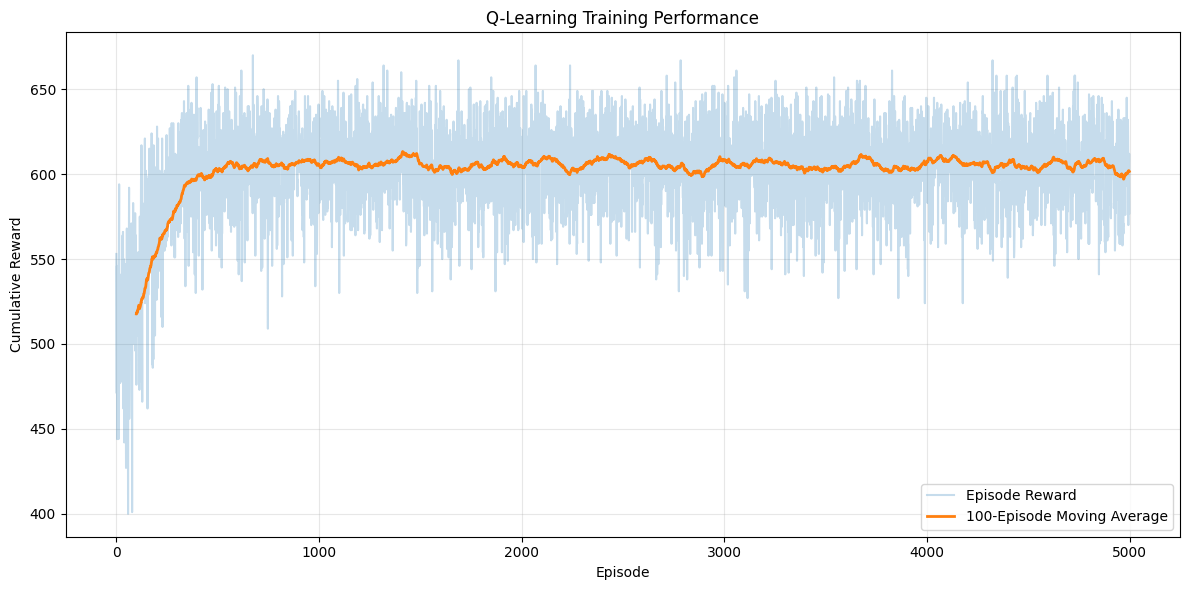

In [18]:
    # ========================================================
    # VISUALIZATIONS
    # ========================================================

    plot_rewards(
        rewards
    )

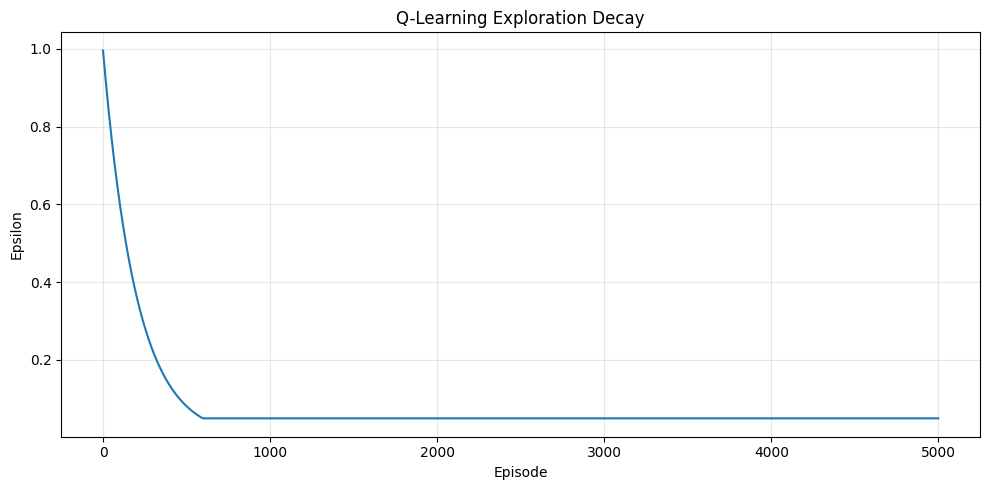

In [19]:
    plot_epsilon(
        epsilon_history
    )

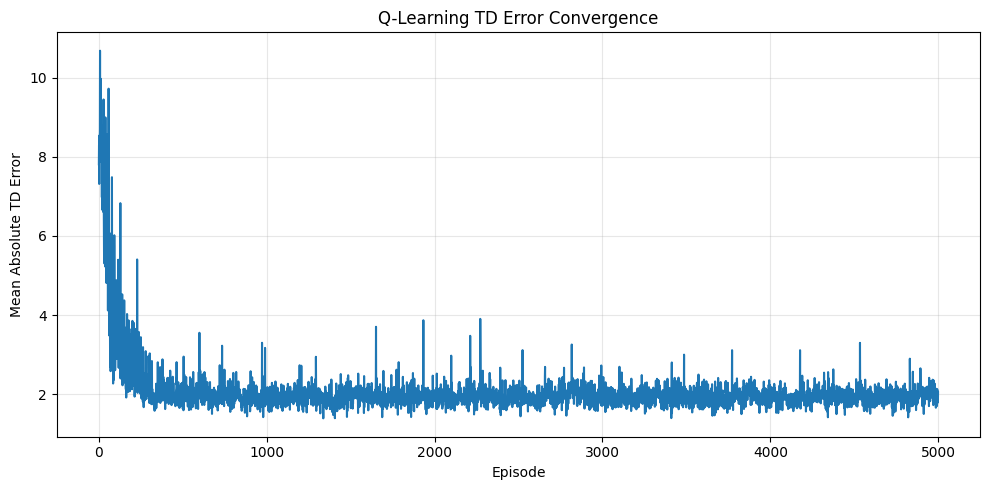

In [20]:
    plot_td_error(
        td_errors
    )


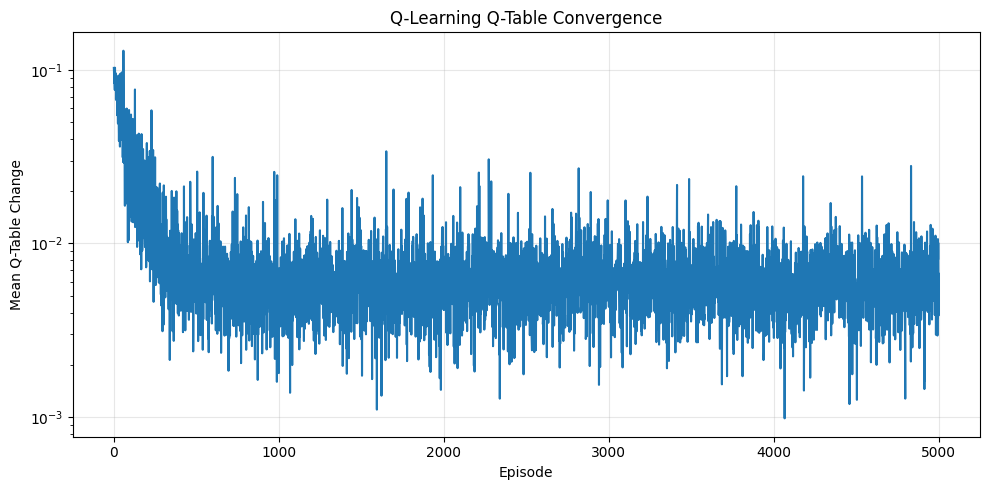

In [21]:
    plot_q_change(
        q_changes
    )


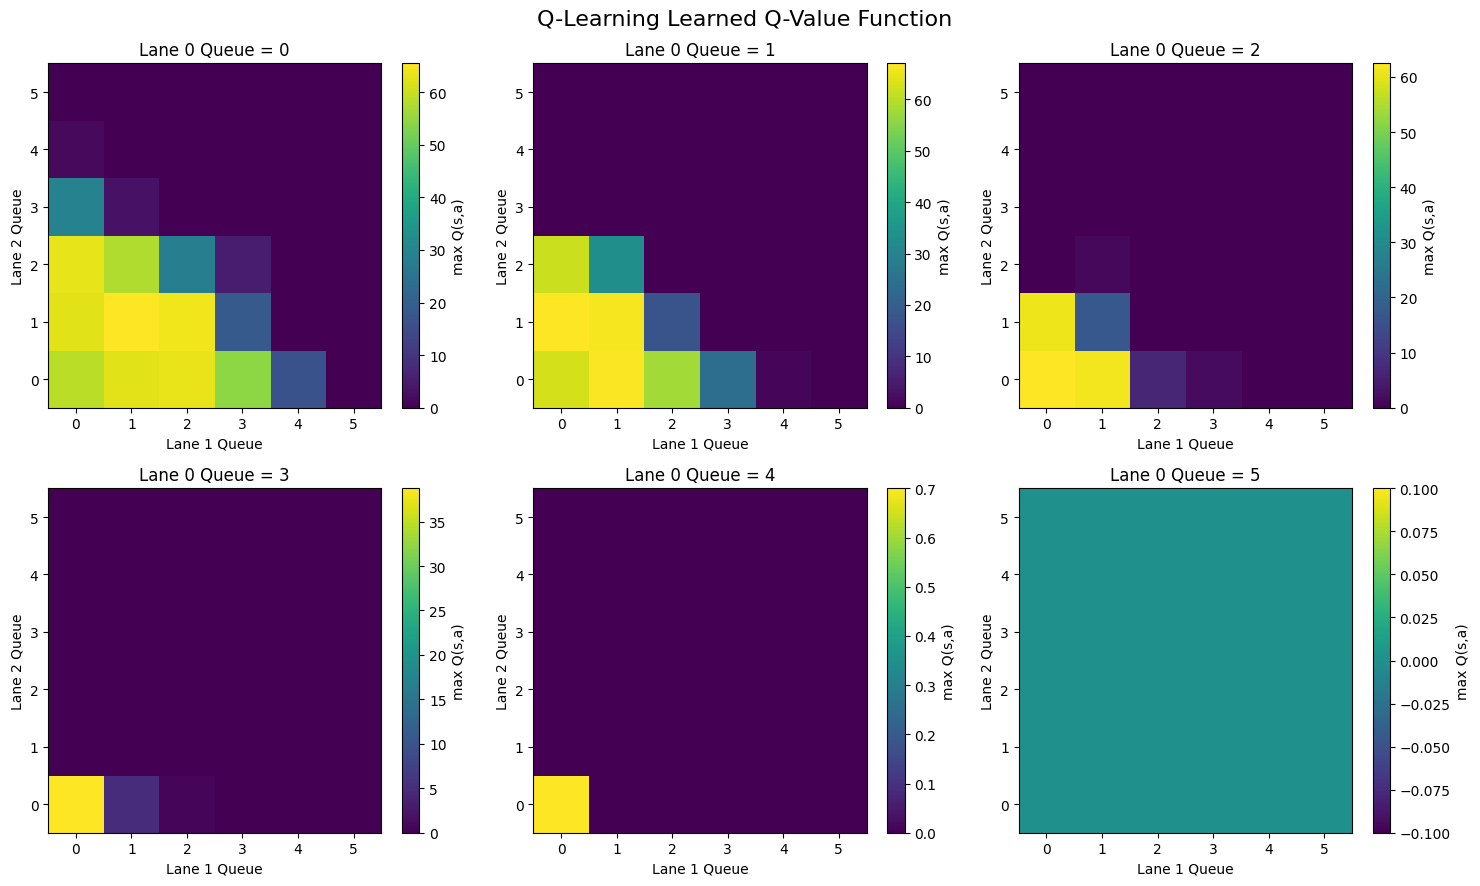

In [22]:
    plot_q_values(
        Q
    )


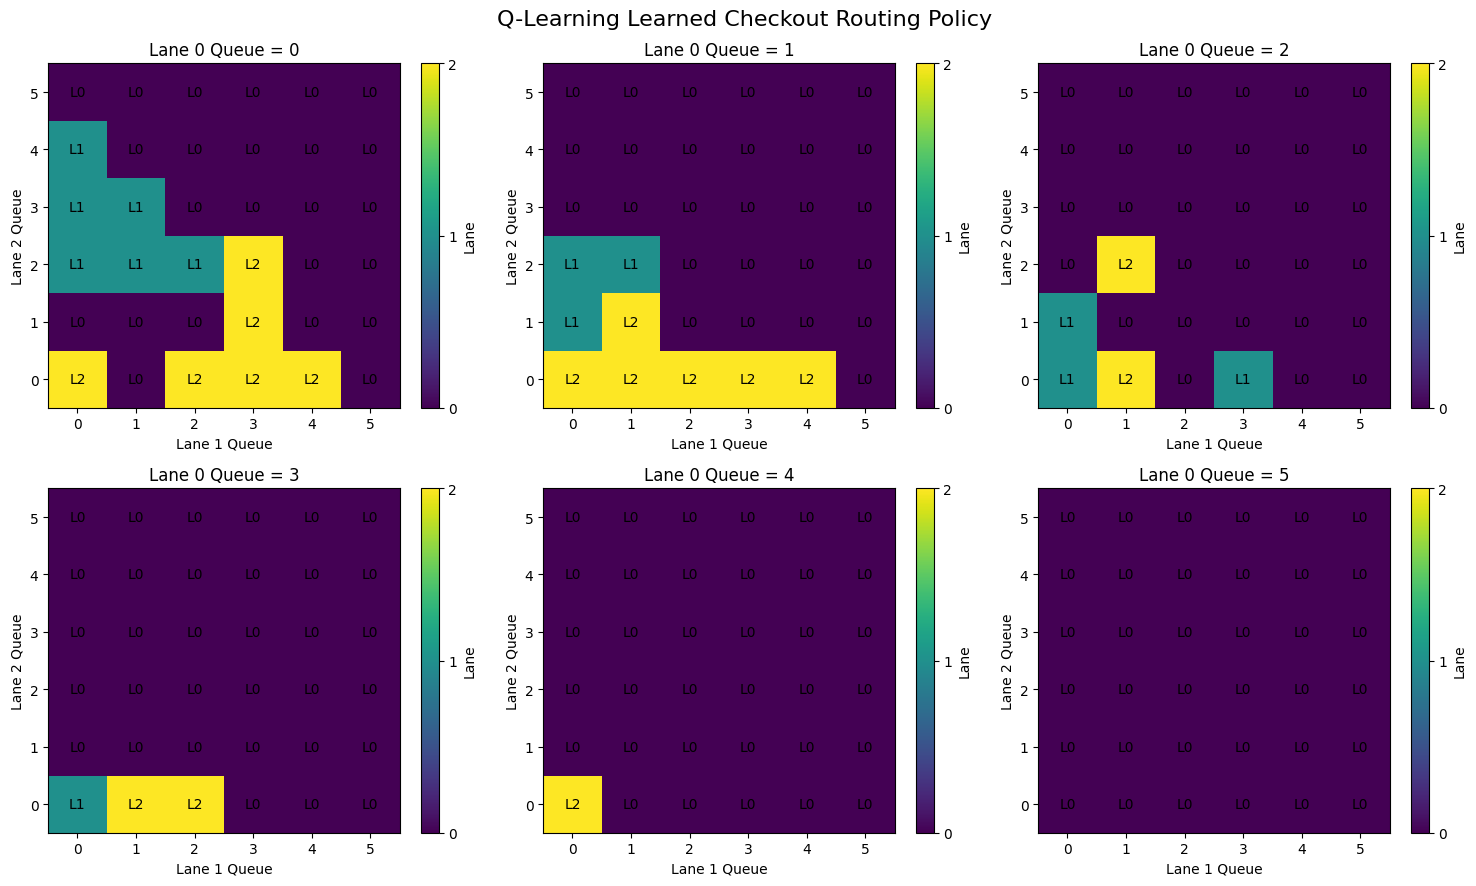

In [23]:

    plot_policy(
        policy
    )


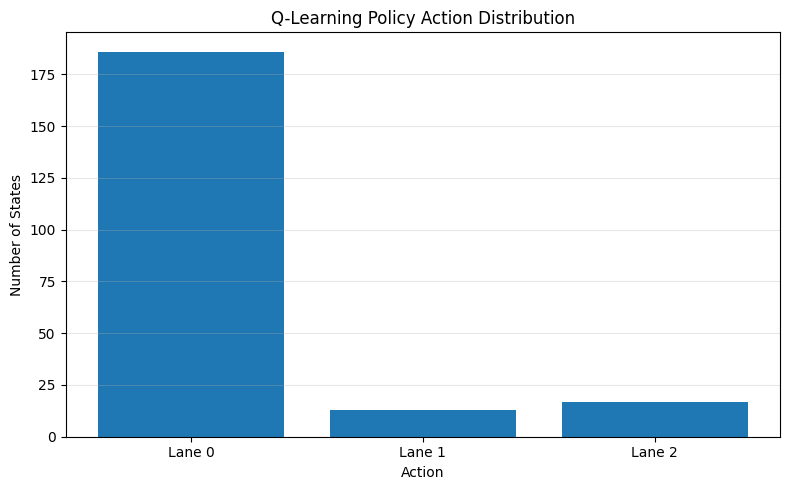

In [24]:


    plot_action_distribution(
        policy
    )


In [14]:
    # ========================================================
    # FINAL RESULTS
    # ========================================================

    print()
    print("=" * 75)
    print("Q-LEARNING TRAINING COMPLETED")
    print("=" * 75)


    print(
        f"Final epsilon       : "
        f"{epsilon_history[-1]:.4f}"
    )


    print(
        f"Final 100-episode reward : "
        f"{np.mean(rewards[-100:]):.4f}"
    )


    print(
        f"Final mean TD error  : "
        f"{td_errors[-1]:.4f}"
    )


    print()
    print(
        "The Q-table represents the learned "
        "action-value function Q(s,a)."
    )


    print(
        "The greedy policy chooses "
        "argmax_a Q(s,a) for every state."
    )


Q-LEARNING TRAINING COMPLETED
Final epsilon       : 0.0500
Final 100-episode reward : 601.6000
Final mean TD error  : 2.0422

The Q-table represents the learned action-value function Q(s,a).
The greedy policy chooses argmax_a Q(s,a) for every state.
